In [95]:
from astropy.coordinates import Distance,SkyCoord
from astropy.time import Time


from astropy import units as astro_unit
import astropy.units as u
import astropy.units.cds as ucds
from astropy.table import *
from dataclasses import dataclass, field
from itertools import combinations
import lsdb
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hdps.catalogs import *
from hdps.skymap import TanSegmentLookup, SegmentationScheme

import warnings
from erfa import ErfaWarning

warnings.filterwarnings('ignore', category=ErfaWarning)

from astropy.utils.exceptions import AstropyWarning

# Silence runtime invalid warnings locally
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='invalid value encountered in pmsafe')


In [39]:
# Cone Search
cone_cen_ra = 40 # degree
cone_cen_dec = 30 # degree
cone_rad = 0.5 # degree

# Open a cone of Gaia to perform the xmatch against.
# Gaia DR3 is a catalog collection; opening the collection’s URL 
# automatically loads an appropriate margin cache. 
gaia_path = "/net/scratch/kmfas/gaia"
gaia_cone = lsdb.open_catalog(gaia_path,
                         columns=["source_id","ref_epoch","ra", "dec", "phot_g_n_obs", "phot_g_mean_mag", "bp_rp","bp_g","g_rp","pmra","pmdec","radial_velocity","parallax"],
                         filters=[["phot_g_mean_mag","<=",19]],
                         search_filter=lsdb.ConeSearch(ra=cone_cen_ra, dec=cone_cen_dec, radius_arcsec=(3600*cone_rad)))

In [40]:
gaia_conedat = gaia_cone.compute()

Computing Catalog:   0%|          | 0/4 [00:00<?, ?it/s]

In [4]:
gaia_conedat

,source_id,ref_epoch,ra,dec,phot_g_n_obs,phot_g_mean_mag,bp_rp,bp_g,g_rp,pmra,pmdec
_healpix_29,,,,,,,,,,,
64138728526729119,128277444633164160,2016.0,39.855212,29.527865,174,18.47184,2.904438,1.721121,1.183317,-7.00381,-10.262551
64138797198760895,128277582072118016,2016.0,39.810539,29.528329,185,18.779486,1.431158,0.638157,0.793001,5.465825,-6.47887
...,...,...,...,...,...,...,...,...,...,...,...
66446897963967688,132893782857222784,2016.0,39.820898,30.470839,218,15.331713,1.260377,0.549518,0.710859,-3.516643,-2.1997
66446932539628406,132893847281385600,2016.0,39.788203,30.460762,232,17.921507,1.5674,0.747068,0.820332,12.643629,-5.532473


## Propagate?

In [24]:
sources = SkyCoord(
    ra=np.array(gaia_conedat['ra'])* u.deg, 
    dec=np.array(gaia_conedat['dec']) * u.deg, 
    pm_ra_cosdec=np.array(gaia_conedat['pmra']) * u.mas / u.yr, # Proper motion in RA (including cos(dec) factor) - gaia pmra is already scaled by that
    pm_dec=np.array(gaia_conedat['pmdec']) * u.mas / u.yr,       # Proper motion in Dec
    obstime=Time('J2016.0'),           # Original catalog/observation epoch
    frame='icrs'
)

# 2. Propagate to a new target epoch
target_epoch = Time('J2026.0')
propagated_sources = sources.apply_space_motion(new_obstime=target_epoch)

# 3. View your new coordinates
#print(f"Original (1991.25): {sources.ra:.4f}, {sources.dec:.4f}")
#print(f"Propagated (2026.0): {propagated_source.ra:.4f}, {propagated_source.dec:.4f}")

/home/kmfas/hdps/.venv/lib/python3.14/site-packages/erfa/core.py:4998: RuntimeWarning: invalid value encountered in pmsafe
  ra2, dec2, pmr2, pmd2, px2, rv2, c_retval = ufunc.pmsafe(


In [25]:
sep = sources.separation(propagated_sources)
print(f"Mean separation between source coords at J2016.0 and propagated coords at J2026.0: {np.nanmean(sep.arcsec):.4f}''")

Mean separation between source coords at J2016.0 and propagated coords at J2026.0: 0.0952''


In [26]:
gaia_conedat['ra']

_healpix_29
64138728526729119    39.855212
64138797198760895    39.810539
                       ...    
66446897963967688    39.820898
66446932539628406    39.788203
Name: ra, Length: 2404, dtype: double[pyarrow]

In [27]:
propagated_sources.ra.value

array([39.85518927, 39.8105565 , 39.76167849, ..., 39.8508012 ,
       39.82088695, 39.78824385], shape=(2404,))

In [29]:
delta_yr

np.float64(10.0)

In [34]:
delta_yr = 2026.0-np.array(gaia_conedat['ref_epoch'])[0]
ra_new = np.array(gaia_conedat['ra'])+(np.array(gaia_conedat['pmra'])*delta_yr/1000.0)#/np.cos(np.deg2rad(gaia_conedat['dec']))
dec_new = np.array(gaia_conedat['dec'])+(np.array(gaia_conedat['pmdec'])*delta_yr/1000.0)
ra_new

array([39.78517353, 39.8651973 , 39.80591217, ..., 40.0048764 ,
       39.78573185, 39.91463939], shape=(2404,))

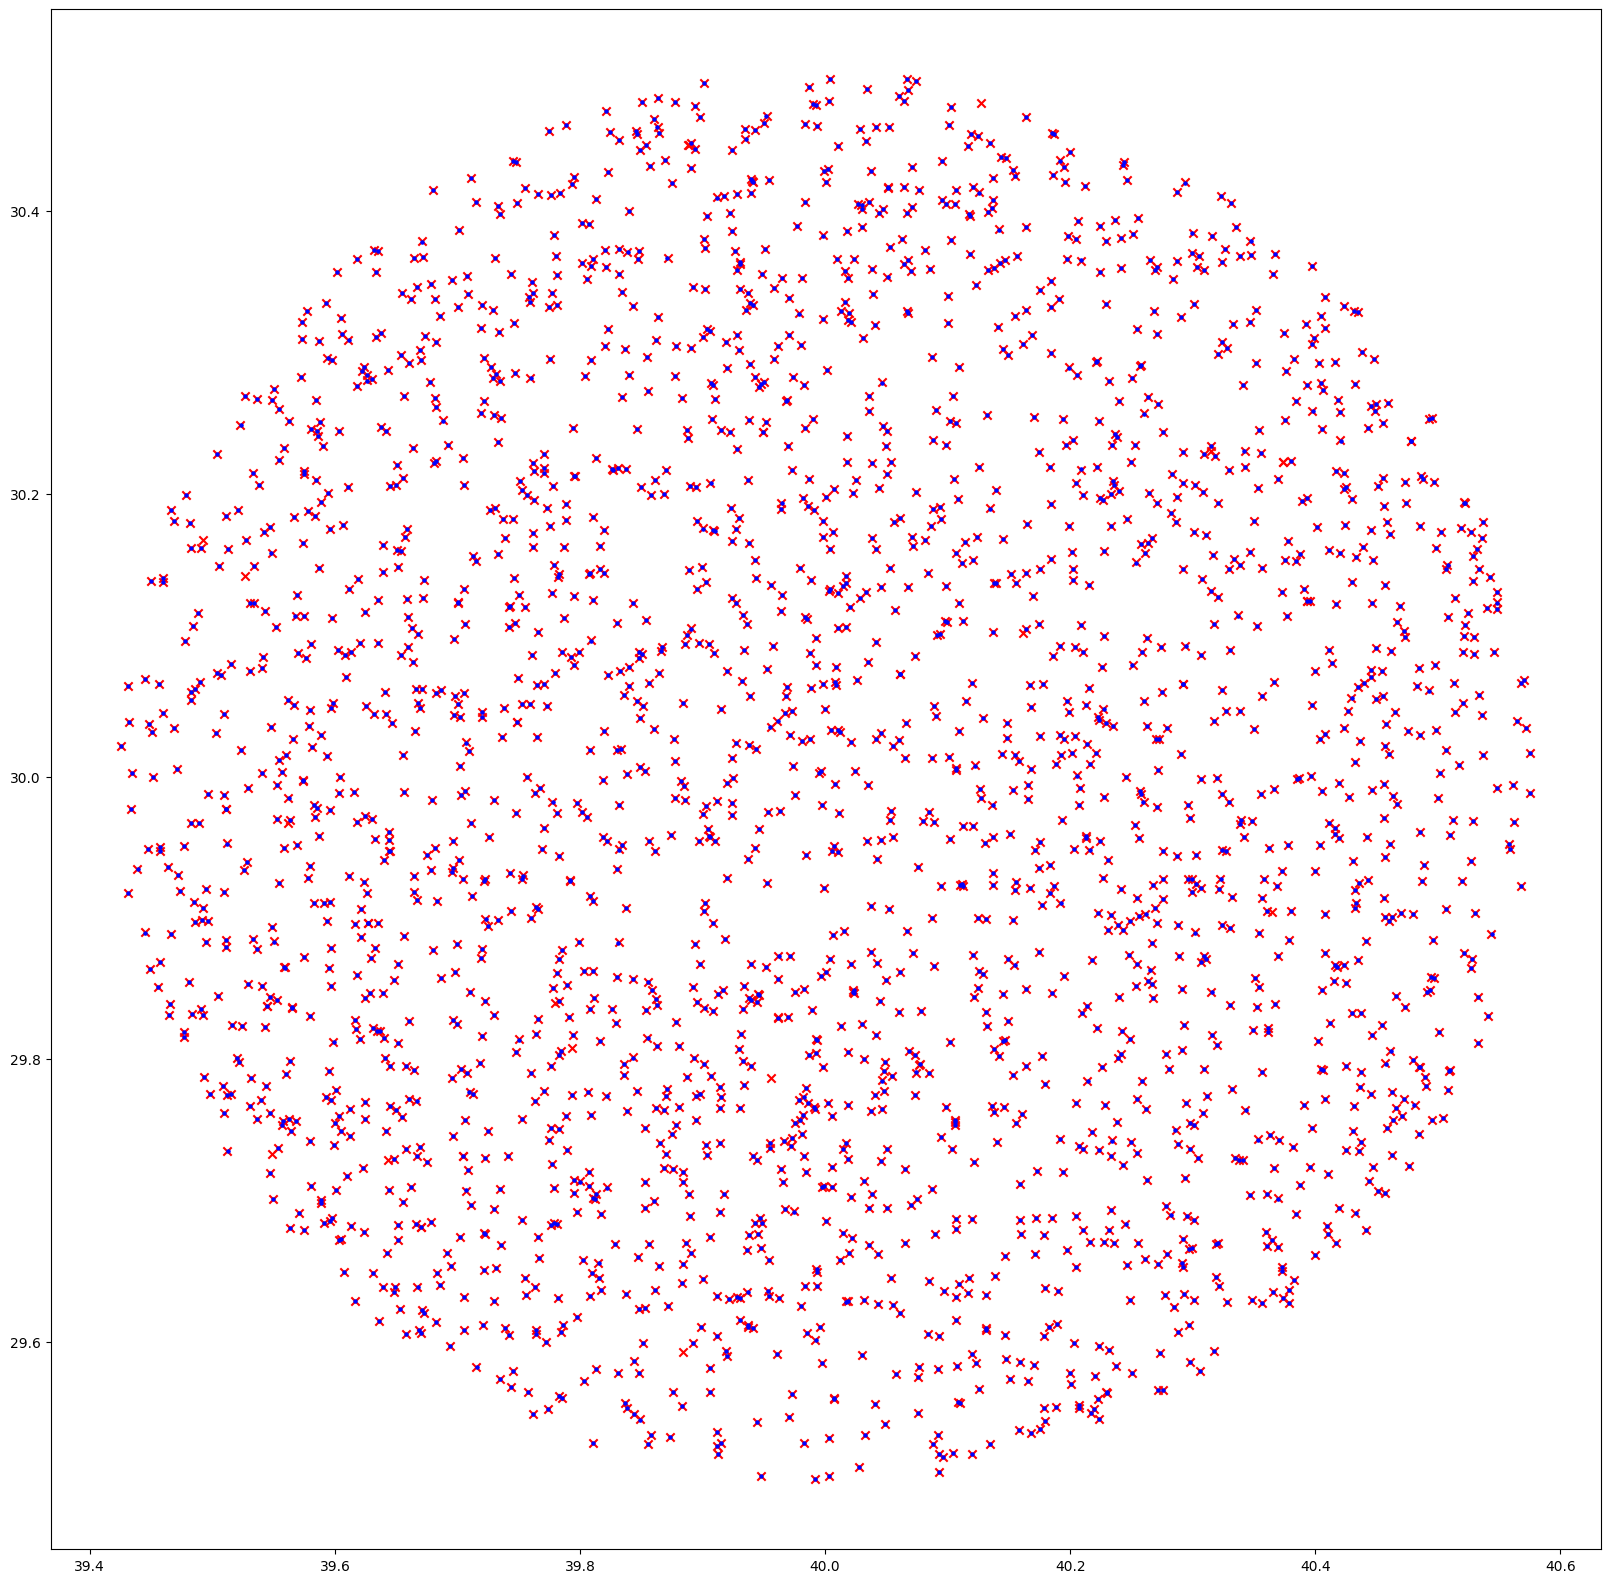

In [13]:
plt.figure(figsize=(20,20))
plt.scatter(np.array(gaia_conedat['ra']),np.array(gaia_conedat['dec']),marker="x",c="red")
plt.scatter(propagated_sources.ra.value,propagated_sources.dec.value,c="blue",s=5)
plt.show()

## Exploring providing minipix for each source, with padding (X'' anulus around each source's coordinates)

In [22]:
tile_arcsec = SegmentationScheme.DEFAULT_TILE_SIZE_ARCSEC
overlap_arcsec = SegmentationScheme.DEFAULT_OVERLAP_ARCSEC
pixel_scale_arcsec = SegmentationScheme.DEFAULT_PIXEL_SCALE
lookup = TanSegmentLookup(
            spacing_deg=(tile_arcsec - overlap_arcsec) / 3600.0,
            pixel_scale_deg=pixel_scale_arcsec / 3600.0,
            dec_min=-90.0,
            ra_min=0.0,
        )

In [25]:
ra_q, dec_q = np.array(gaia_conedat['ra']),np.array(gaia_conedat['dec'])
pad_arcsec=10
if pad_arcsec > 0:
    # 8-point dither at the pad radius: the union of containing cells
    # over source ± pad covers every cell the padded footprint touches
    d = pad_arcsec / 3600.0
    d_ra = d / np.maximum(np.cos(np.radians(dec_q)), 1e-6)
    ras, decs = [ra_q], [dec_q]
    for fx, fy in ((-1, -1), (-1, 0), (-1, 1), (0, -1),
                    (0, 1), (1, -1), (1, 0), (1, 1)):
        added_ras = ra_q + fx * d_ra
        added_decs = dec_q + fy * d
        print(len(added_ras),len(added_decs))
        ras.append(added_ras)
        decs.append(added_decs)
    ra_q = np.concatenate(ras)
    dec_q = np.concatenate(decs)
tanseg_ids, local_idxs = lookup.query_batch(ra_q, dec_q)

2404 2404
2404 2404
2404 2404
2404 2404
2404 2404
2404 2404
2404 2404
2404 2404


In [24]:
len(tanseg_ids),len(np.array(gaia_conedat['ra']))

(21636, 2404)

## Synthetic Photometry?

### Gaia -> Argus color transformation

In [30]:
def get_synphot(dframe):

    def linear_func(x,a,b):
        return a+(x*b)

    a_grho = -0.2144863922451342
    b_grho = 0.5185776973884502

    a_gbeta = -0.01588226688060276
    b_gbeta = 0.5185776973884502

    gaia_g = np.array(dframe['phot_g_mean_mag'])#[0]
    gaia_bp_rp = np.array(dframe['bp_rp'])#[0]
    argus_rho = gaia_g - linear_func(gaia_bp_rp,a_grho,b_grho)
    argus_beta = gaia_g - linear_func(gaia_bp_rp,a_gbeta,b_gbeta)

    dframe['argus_beta_synth'] = argus_beta
    dframe['argus_rho_synth'] = argus_rho

    return(dframe)

gaia_conedat_withsynth = get_synphot(gaia_conedat)
gaia_conedat_withsynth

,source_id,ref_epoch,ra,dec,phot_g_n_obs,phot_g_mean_mag,bp_rp,bp_g,g_rp,pmra,pmdec,argus_beta_synth,argus_rho_synth
_healpix_29,,,,,,,,,,,,,
64138728526729119,128277444633164160,2016.0,39.855212,29.527865,174,18.47184,2.904438,1.721121,1.183317,-7.00381,-10.262551,16.981544,17.180149
64138797198760895,128277582072118016,2016.0,39.810539,29.528329,185,18.779486,1.431158,0.638157,0.793001,5.465825,-6.47887,18.053202,18.251806
...,...,...,...,...,...,...,...,...,...,...,...,...,...
66446897963967688,132893782857222784,2016.0,39.820898,30.470839,218,15.331713,1.260377,0.549518,0.710859,-3.516643,-2.1997,14.693992,14.892595
66446932539628406,132893847281385600,2016.0,39.788203,30.460762,232,17.921507,1.5674,0.747068,0.820332,12.643629,-5.532473,17.124571,17.323175


## Get MOC of tile coverage and query Gaia with LSDB

In [15]:
import mocpy
from mocpy import MOC
from hdps.skymap import SegmentationScheme,TanSegmentLookup

In [16]:
scheme = SegmentationScheme.all_sky()


Loading SegmentationScheme from cache: /home/kmfas/.hdps/skymap_cache/segscheme_v2_tile1800p0_overlap28p125_ps0p87890625_ra0-360_dec-90-90.fits
Loaded 170448 tiles from cache


In [17]:
# define sky tiling parameters
tile_size_arcsec = scheme.DEFAULT_TILE_SIZE_ARCSEC
overlap_arcsec = scheme.DEFAULT_OVERLAP_ARCSEC
pixel_scale = scheme.DEFAULT_PIXEL_SCALE 

# define the lookup
lookup = TanSegmentLookup(
    spacing_deg=(tile_size_arcsec-overlap_arcsec)/3600, # (tile_size - overlap) in degrees
    pixel_scale_deg=pixel_scale/3600,                    # arcsec to degrees
    dec_min=-90.0,
    ra_min=0
) 

In [20]:
tiles = pd.read_parquet("/home/kmfas/aic_dev/argus_segments.parquet")
id_set = set(tiles['seg'])
tile_matches = [(i, d) for i, d in enumerate(scheme.tiles) if d["tile_id"] in id_set]

mocs = []
for idx,tile in tile_matches:
    corners = scheme._calculate_tile_footprint(tile,idx)
    #print(corners)
    moc = MOC.from_polygon(corners[:,0]*u.degree, corners[:,1]*u.degree, max_depth=7)
    mocs.append(moc)

union_moc = MOC.union(*mocs)

In [22]:
ALL_SKY = 4 * np.pi * u.steradian

# Calculate area
area = union_moc.sky_fraction * ALL_SKY

# Convert to square degrees
area_sq_deg = area.to(u.deg**2).value
print(f"Area: {area_sq_deg} deg², sky fraction {union_moc.sky_fraction}")

Area: 992.464735462205 deg², sky fraction 0.02405802408854167


In [ ]:
#union_moc.save("/home/kmfas/aic_dev/aic_refcat_build/argus_segments_moc.fits",format="fits") # this is order 6
from astropy.io import fits
file = fits.open("/home/kmfas/aic_dev/aic_refcat_build/argus_segments_moc.fits")
file.close()

In [25]:
gaia = lsdb.open_catalog("/net/scratch/kmfas/gaia",
                         columns=["source_id","ref_epoch","ra", "dec", "phot_g_n_obs", "phot_g_mean_mag", "bp_rp","bp_g","g_rp","pmra","pmdec"],
                         filters=[["phot_g_mean_mag","<=",20]])
result = gaia.moc_search(union_moc)

In [89]:

def get_synphot(dframe):

    def linear_func(x,a,b):
        return a+(x*b)

    # synthetic photometry

    a_grho = -0.2144863922451342
    b_grho = 0.5185776973884502
    a_gbeta = -0.01588226688060276
    b_gbeta = 0.5185776973884502

    gaia_g = np.array(dframe['phot_g_mean_mag'])#[0]
    gaia_bp_rp = np.array(dframe['bp_rp'])#[0]
    argus_rho = gaia_g - linear_func(gaia_bp_rp,a_grho,b_grho)
    argus_beta = gaia_g - linear_func(gaia_bp_rp,a_gbeta,b_gbeta)

    # propagate!

    delta_yr = 2026.0-np.array(dframe['ref_epoch'])[0]
    ra_new = np.array(dframe['ra'])+(dframe['pmra']*delta_yr/1000.0/np.cos(np.deg2rad(gaia2['dec'])))
    dec_new = np.array(dframe['dec'])+(dframe['pmdec']*delta_yr/1000.0)

    
    dframe['argus_beta_synth'] = argus_beta
    dframe['argus_rho_synth'] = argus_rho

    return(dframe)


def get_synphot_and_propagate(dframe):

    if len(dframe) == 0:
        col_type = np.array([], dtype=float)
        return dframe[["ra", "dec"]].assign(ra_corr=col_type, dec_corr=col_type)

    def linear_func(x,a,b):
        return a+(x*b)

    # synthetic photometry

    a_grho = -0.2144863922451342
    b_grho = 0.5185776973884502
    a_gbeta = -0.01588226688060276
    b_gbeta = 0.5185776973884502

    gaia_g = np.array(dframe['phot_g_mean_mag'])#[0]
    gaia_bp_rp = np.array(dframe['bp_rp'])#[0]
    argus_rho = gaia_g - linear_func(gaia_bp_rp,a_grho,b_grho)
    argus_beta = gaia_g - linear_func(gaia_bp_rp,a_gbeta,b_gbeta)

    # propagate 

    sources = SkyCoord(
        ra=np.array(dframe['ra'])* u.deg, 
        dec=np.array(dframe['dec']) * u.deg, 
        pm_ra_cosdec=np.array(dframe['pmra']) * u.mas / u.yr, # Proper motion in RA (including cos(dec) factor)
        pm_dec=np.array(dframe['pmdec']) * u.mas / u.yr,       # Proper motion in Dec
        #radial_velocity=np.array(dframe['radial_velocity'])*u.km/u.second,
        #distance=Distance(parallax=np.array(dframe['parallax'])*u.marcsec,allow_negative=True),
        obstime=Time('J2016.0'),           # Original catalog/observation epoch
        frame='icrs'
    )

    target_epoch = Time('J2026.0')
    propagated_sources = sources.apply_space_motion(new_obstime=target_epoch)

    #delta_yr = 2026.0-np.array(dframe['ref_epoch'])[0]
    #ra_new = np.array(dframe['ra'])+(dframe['pmra']*delta_yr/1000.0/np.cos(np.deg2rad(gaia2['dec'])))
    #dec_new = np.array(dframe['dec'])+(dframe['pmdec']*delta_yr/1000.0)


    dframe = dframe.drop(columns=["ref_epoch"])
    dframe['argus_beta_synth'] = argus_beta
    dframe['argus_rho_synth'] = argus_rho
    dframe['ra_prop'] = propagated_sources.ra.value
    dframe['dec_prop'] = propagated_sources.dec.value
    dframe['epoch'] = 2026.0

    dframe.dropna(subset=["ra","dec"], inplace=True)

    return(dframe)

In [96]:
meta = get_synphot_and_propagate(gaia_conedat).head(0)

/home/kmfas/hdps/.venv/lib/python3.14/site-packages/erfa/core.py:4998: RuntimeWarning: invalid value encountered in pmsafe
  ra2, dec2, pmr2, pmd2, px2, rv2, c_retval = ufunc.pmsafe(


In [ ]:
#np.array(meta.dtypes)
#np.array(meta.columns)

array(['source_id', 'ra', 'dec', 'phot_g_n_obs', 'phot_g_mean_mag',
       'bp_rp', 'bp_g', 'g_rp', 'pmra', 'pmdec', 'radial_velocity',
       'parallax', 'argus_beta_synth', 'argus_rho_synth', 'ra_prop',
       'dec_prop', 'epoch'], dtype=object)

In [84]:
gaia_synprop_dtypes = np.array(["int64[pyarrow]", "double[pyarrow]", "double[pyarrow]", "int16[pyarrow]",
       "float[pyarrow]", "float[pyarrow]", "float[pyarrow]", "float[pyarrow]",
       "double[pyarrow]", "double[pyarrow]", "float[pyarrow]", "double[pyarrow]",
       'float32', 'float32', 'float64',
       'float64', 'float64'])
gaia_synprop_columns = np.array(['source_id', 'ra', 'dec', 'phot_g_n_obs', 'phot_g_mean_mag',
       'bp_rp', 'bp_g', 'g_rp', 'pmra', 'pmdec', 'radial_velocity',
       'parallax', 'argus_beta_synth', 'argus_rho_synth', 'ra_prop',
       'dec_prop', 'epoch'])

scratch_meta_gaia_synprop = pd.DataFrame({col: pd.Series(dtype=dtp) for col,dtp in zip(gaia_synprop_columns,gaia_synprop_dtypes)})


In [93]:
test = gaia_cone.map_partitions(get_synphot_and_propagate,meta=scratch_meta_gaia_synprop)
tt = test.compute()
tt

Computing Catalog:   0%|          | 0/6 [00:00<?, ?it/s]

/home/kmfas/hdps/.venv/lib/python3.14/site-packages/erfa/core.py:4998: RuntimeWarning: invalid value encountered in pmsafe
  ra2, dec2, pmr2, pmd2, px2, rv2, c_retval = ufunc.pmsafe(


,source_id,ra,dec,phot_g_n_obs,phot_g_mean_mag,bp_rp,bp_g,g_rp,pmra,pmdec,radial_velocity,parallax,argus_beta_synth,argus_rho_synth,ra_prop,dec_prop,epoch
_healpix_29,,,,,,,,,,,,,,,,,
64138728526729119,128277444633164160,39.855212,29.527865,174,18.47184,2.904438,1.721121,1.183317,-7.00381,-10.262551,<NA>,1.9724,16.981544,17.180149,39.855189,29.527837,2026.0
64138797198760895,128277582072118016,39.810539,29.528329,185,18.779486,1.431158,0.638157,0.793001,5.465825,-6.47887,<NA>,0.957253,18.053202,18.251806,39.810557,29.528311,2026.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66446897963967688,132893782857222784,39.820898,30.470839,218,15.331713,1.260377,0.549518,0.710859,-3.516643,-2.1997,<NA>,1.616626,14.693992,14.892595,39.820887,30.470833,2026.0
66446932539628406,132893847281385600,39.788203,30.460762,232,17.921507,1.5674,0.747068,0.820332,12.643629,-5.532473,<NA>,0.704477,17.124571,17.323175,39.788244,30.460747,2026.0


In [91]:
np.mean(np.array(gaia_conedat['pmra']))

np.float64(nan)

In [55]:
gaia_dr3 = lsdb.open_catalog(
    "s3://stpubdata/gaia/gaia_dr3/public/hats",
    columns=["pmra", "pmdec", "radial_velocity", "parallax"],
    filters=[("pm", "<", 1000.0), ("parallax", ">", 0.0)],
).query("radial_velocity.notna()")

In [57]:
import astropy.units as units

In [70]:
gaia_dr3_epoch = 2016.0
dp1_epoch=2026.0

def propagate_epoch(df, *, start, end):
    if len(df) == 0:
        col_type = np.array([], dtype=float)
        return df[["ra", "dec"]].assign(ra_corr=col_type, dec_corr=col_type)

    start_coord = SkyCoord(
        ra=df["ra"].to_numpy() * units.deg,
        dec=df["dec"].to_numpy() * units.deg,
        pm_ra_cosdec=df["pmra"].to_numpy() * units.marcsec / units.year,
        pm_dec=df["pmdec"].to_numpy() * units.marcsec / units.year,
        radial_velocity=df["radial_velocity"].to_numpy() * units.km / units.s,
        distance=Distance(parallax=df["parallax"].to_numpy() * units.marcsec,allow_negative=True),
        obstime=Time(start, format="byear"),
        frame="icrs",
    )
    end_coord = start_coord.apply_space_motion(new_obstime=Time(end, format="byear"))
    df["ra_corr"] = end_coord.ra.deg
    df["dec_corr"] = end_coord.dec.deg

    # Return only the columns we need going forward
    return df[["ra", "dec", "ra_corr", "dec_corr"]]


propagated_gaia = gaia_cone.map_partitions(propagate_epoch, start=gaia_dr3_epoch, end=dp1_epoch)
propagated_gaia

,ra,dec,ra_corr,dec_corr
npartitions=1,,,,
"Order: 2, Pixel: 3",double[pyarrow],double[pyarrow],float64,float64


In [71]:
propagated_gaia.compute()

Computing Catalog:   0%|          | 0/6 [00:00<?, ?it/s]

/home/kmfas/hdps/.venv/lib/python3.14/site-packages/erfa/core.py:4998: RuntimeWarning: invalid value encountered in pmsafe
  ra2, dec2, pmr2, pmd2, px2, rv2, c_retval = ufunc.pmsafe(


,ra,dec,ra_corr,dec_corr
_healpix_29,,,,
64138728526729119,39.855212,29.527865,NaN,NaN
64138797198760895,39.810539,29.528329,NaN,NaN
...,...,...,...,...
66446897963967688,39.820898,30.470839,NaN,NaN
66446932539628406,39.788203,30.460762,NaN,NaN
